# $K_d, K_p$ Constants Analysis

## ToDo
- 실제 Loss 기반 최적 $K_d, K_p$ 계산 수식 도출 및 최적값 계산
- 실제 Loss 기반 최적 $K_d, K_p$ 변화 양상 파악
- PAPE 기반 $G^h, G$ 계산
- PAPE 기반 $G^h, G$과 실제 Loss 기반 $G^h, G$ 차이 모델링
- PAPE 값 보정 방안 도출

### Optimal(이상적인) $K_d, K_p$ 계산 수식 도출
- RCCDA가 제안하는 이상적인 G값의 계산은 $t_{-1}$시점에 학습한 모델의 $t_{1}$ 시점의 Loss와 $t_{-1}$시점에 학습한 모델의 가중치를 $t_0$ 시점에 발생한 데이터 드리프트를 보정한 $t_0$시점의 Loss 차이임
- 따라서 이상적인 $K_p, K_d$의 계산 방법은 아래와 같음
- $K_p(loss(t_0) - min(loss)) + K_d(loss(t_0) - loss(t_{-1}))= G^{hat} = G = loss_{keep} - loss_{retrain}$
- $K_p(loss(t_0) - min(loss))  = loss_{keep}$
- $K_d(loss(t_0) - loss(t_{-1})) = loss_{retrain}$
- $K_p = \frac{loss_{keep}}{(loss(t_0) - min(loss))}$
- $K_d = \frac{loss_{retrain}}{(loss(t_0) - loss(t_{-1})}$

### Optimal $K_d, K_p$ 계산
- APIGraph 2015, 2016 데이터 활용
- $G^{hat} = G$인 경우

In [397]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [398]:
years = [15, 16]

In [399]:
# load keep/retrain losses
keep_loss = pd.concat([pd.read_csv(f'./results/keep_monthly_{i}.csv') for i in years], axis=0)
keep_loss.reset_index(inplace=True)
retrain_loss = pd.concat([pd.read_csv(f'./results/retrain_monthly_{i}.csv') for i in years], axis=0)
retrain_loss.reset_index(inplace=True)

In [400]:
def get_min_loss(losses, idx):
    '''
    define get min loss function to get minimum loss.
    this function return the minimum loss from inputed losses.
    but if min loss is same as current loss, it returns second minimum loss to prevent inf value
    '''
    if losses['loss'][idx-1] == min(losses['loss'][:idx-1]):
        return sorted(losses['loss'][:idx-1])[1]
    else:
        return min(losses['loss'][:idx-1])

In [401]:
kp_true = []
kd_true = []
for i in range(2, len(keep_loss)):
    kp = keep_loss['loss'][i] / (keep_loss['loss'][i-1] - get_min_loss(keep_loss, i))
    kd = retrain_loss['loss'][i] / (keep_loss['loss'][i-1] - keep_loss['loss'][i-2])
    kp_true.append(kp)
    kd_true.append(kd)

In [402]:
keep_loss['kp_optimal'] = [0] * 2 + kp_true

In [403]:
keep_loss['kd_optimal'] = [0] * 2 + kd_true

### 실제 사용 가능한 $K_d, K_p$ 계산 수식 도출
- Optimal $K_d, K_p$를 계산하려면 $loss_{keep, t + 1}$과 $loss_{retrain, t + 1}$을 알고 있어야함
- 하지만 $t + 1$시점의 Loss는 미래이므로 알 수 없음
- 따라서 $t$시점까지 계산해온 $G^{hat}$의 평균이 기반으로 $t + 1$ 시점의 $G^{hat}(t + 1)$과 동일하다고 가정
- 다만 $K_p(t)$의 경우, 최종적으로 $loss_{keep}$을 계산하기 위해서는 $loss_{retrain}$이 요구됨. 하지만 이는 해당 시점에 알 수 없는 값임.
- 따라서 $loss_{retrain}$의 값을 가장 최근에 측정(추정)한 loss인 $PAPE(t_0)$로 치환하여 사용
- 이 경우, $loss_{keep} =$  $(Avg$ $G^{hat}$  $= loss_{keep} - loss_{retrain}) + PAPE(t_0)$
- 이 경우, $loss_{retrain} =$  $-(Avg$ $G^{hat}$  $= loss_{keep} - loss_{retrain}) - PAPE(t_0)$



- 따라서 $K_p(t) = \frac{Avg G^{hat} + PAPE(t_0)}{PAPE(t_0) - loss_{min}}$
- 따라서 $K_d(t) = \frac{PAPE(t_0) - Avg G^{hat}}{PAPE(t_0) + loss(t_{-1})}$

### Practical $K_d, K_p$ 계산
- APIGraph 2015, 2016 데이터 및 PAPE 활용

In [404]:
gain_true = pd.concat([pd.read_csv(f'./results/gain_monthly_{i}.csv') for i in years], axis=0)
gain_true.reset_index(inplace=True)

In [405]:
pape = pd.concat([pd.read_csv(f'./results/confusion_matrix_{i}.csv') for i in years], axis=0)
pape.reset_index(inplace=True)

In [406]:
uniform_pape = pape[pape['input_variant']=='all_binary__uniform'][pape['seed']==11].reset_index()
dre_pape = pape[pape['input_variant']=='all_binary__dre'][pape['seed']==11].reset_index()

/tmp/ipykernel_48223/261697815.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  uniform_pape = pape[pape['input_variant']=='all_binary__uniform'][pape['seed']==11].reset_index()
/tmp/ipykernel_48223/261697815.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  dre_pape = pape[pape['input_variant']=='all_binary__dre'][pape['seed']==11].reset_index()


In [407]:
def K_p_fomula(avg_gain, cur_loss, min_loss):
    return (avg_gain + cur_loss) / (cur_loss - min_loss)

def K_d_fomula(avg_gain, cur_loss, prev_loss):
    return (cur_loss - avg_gain) / (cur_loss + prev_loss)


In [408]:
def gain_estimate(cur_loss, min_loss, prev_loss, kp, kd):
    est_loss_keep = kp * (cur_loss - min_loss)
    est_loss_retrain = kd * (cur_loss - prev_loss)
    return est_loss_keep, est_loss_retrain, est_loss_keep + est_loss_retrain

In [409]:
kd_pape_uni = []
kp_pape_uni = []
avg_gain = sum(keep_loss['loss'][:2] - retrain_loss['loss'][:2]) / 2
est_gain_uni_assume = []
est_loss_keep_uni = []
est_loss_retrain_uni = []
for i in range(2, len(keep_loss)):
    cur_loss = uniform_pape['estimated_loss'][i-1]
    prev_loss = keep_loss['loss'][i-2]
    min_loss = get_min_loss(keep_loss, i)
    kp = K_p_fomula(avg_gain, cur_loss, min_loss)
    kd = K_d_fomula(avg_gain, cur_loss, cur_loss)
    est_lk, est_lr, est_gain = gain_estimate(cur_loss, min_loss, prev_loss, kp, kd)
    kp_pape_uni.append(kp)
    kd_pape_uni.append(kd)
    est_gain_uni_assume.append(est_gain)
    est_loss_keep_uni.append(est_lk)
    est_loss_retrain_uni.append(est_lr)
    avg_gain = (avg_gain * i + est_gain) / (i + 1)


In [410]:
kd_pape_uni = []
kp_pape_uni = []
avg_gain = sum(keep_loss['loss'][:2] - retrain_loss['loss'][:2]) / 2
est_gain_uni = []
est_loss_keep_uni = []
est_loss_retrain_uni = []
for i in range(2, len(keep_loss)):
    cur_loss = uniform_pape['estimated_loss'][i-1]
    cur_loss_r = keep_loss['loss'][i - 1]
    prev_loss = keep_loss['loss'][i-2]
    min_loss = get_min_loss(keep_loss, i)
    kp = K_p_fomula(avg_gain, cur_loss, min_loss)
    kd = K_d_fomula(avg_gain, cur_loss, cur_loss)
    est_lk, est_lr, est_gain = gain_estimate(cur_loss, min_loss, prev_loss, kp, kd)
    kp_pape_uni.append(kp)
    kd_pape_uni.append(kd)
    est_gain_uni.append(est_gain)
    est_loss_keep_uni.append(est_lk)
    est_loss_retrain_uni.append(est_lr)
    avg_gain = (avg_gain * i + gain_true['g_real'][i-2]) / (i + 1)


In [411]:
kd_pape_dre = []
kp_pape_dre = []
avg_gain = sum(keep_loss['loss'][:2] - retrain_loss['loss'][:2]) / 2
est_gain_dre_assume = []
est_loss_keep_dre = []
est_loss_retrain_dre = []
for i in range(2, len(keep_loss)):
    cur_loss = dre_pape['estimated_loss'][i-1]
    prev_loss = keep_loss['loss'][i-2]
    min_loss = get_min_loss(keep_loss, i)
    kp = K_p_fomula(avg_gain, cur_loss, min_loss)
    kd = K_d_fomula(avg_gain, cur_loss, cur_loss)
    est_lk, est_lr, est_gain = gain_estimate(cur_loss, min_loss, prev_loss, kp, kd)
    kp_pape_dre.append(kp)
    kd_pape_dre.append(kd)
    est_gain_dre_assume.append(est_gain)
    avg_gain = (avg_gain * i + est_gain) / (i + 1)


In [412]:
kd_pape_dre = []
kp_pape_dre = []
avg_gain = sum(keep_loss['loss'][:1] - retrain_loss['loss'][:1]) / 1
est_gain_dre = []
est_loss_keep_dre = []
est_loss_retrain_dre = []
for i in range(2, len(keep_loss)):
    cur_loss = dre_pape['estimated_loss'][i-1]
    prev_loss = keep_loss['loss'][i-2]
    min_loss = get_min_loss(keep_loss, i)
    kp = K_p_fomula(avg_gain, cur_loss, min_loss)
    kd = K_d_fomula(avg_gain, cur_loss, cur_loss)
    est_lk, est_lr, est_gain = gain_estimate(cur_loss, min_loss, prev_loss, kp, kd)
    kp_pape_dre.append(kp)
    kd_pape_dre.append(kd)
    est_gain_dre.append(est_gain)
    est_loss_keep_dre.append(est_lk)
    est_loss_retrain_dre.append(est_lr)
    avg_gain = (avg_gain * i + gain_true['g_real'][i-2]) / (i + 1)


### Optimal & practical 성능 비교

Text(0.5, 1.0, 'Optimal K_p by month')

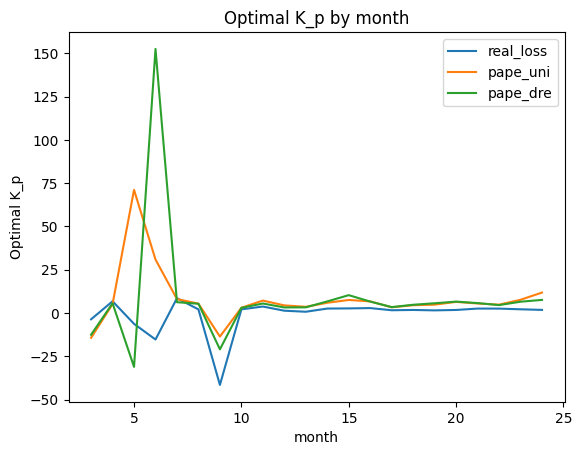

In [413]:
plt.plot([i for i in range(3, len(keep_loss)+1)], kp_true)
plt.plot([i for i in range(3, len(keep_loss)+1)], kp_pape_uni)
plt.plot([i for i in range(3, len(keep_loss)+1)], kp_pape_dre)
plt.legend(['real_loss', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('Optimal K_p')
plt.title('Optimal K_p by month')

Text(0.5, 1.0, 'Optimal K_d by month')

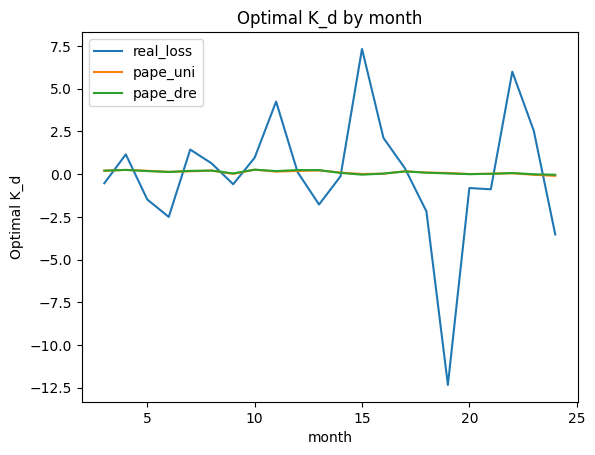

In [414]:
plt.plot([i for i in range(3, len(keep_loss)+1)], kd_true)
plt.plot([i for i in range(3, len(keep_loss)+1)], kd_pape_uni)
plt.plot([i for i in range(3, len(keep_loss)+1)], kd_pape_dre)
plt.legend(['real_loss', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('Optimal K_d')
plt.title('Optimal K_d by month')

Text(0.5, 1.0, 'Gain by month, calc avg Gain with estimated gain')

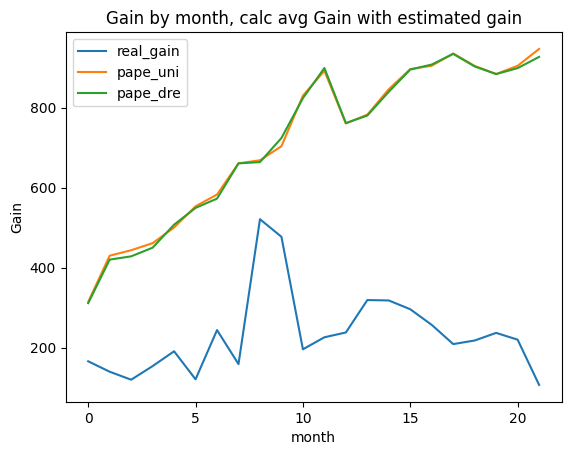

In [415]:
plt.plot([i for i in range(len(gain_true)-2)], gain_true['g_real'][2:])
plt.plot([i for i in range(len(gain_true)-2)], est_gain_uni_assume)
plt.plot([i for i in range(len(gain_true)-2)], est_gain_dre_assume)
plt.legend(['real_gain', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('Gain')
plt.title('Gain by month, calc avg Gain with estimated gain')

Text(0.5, 1.0, 'Gain by month, calc avg Gain with true gain')

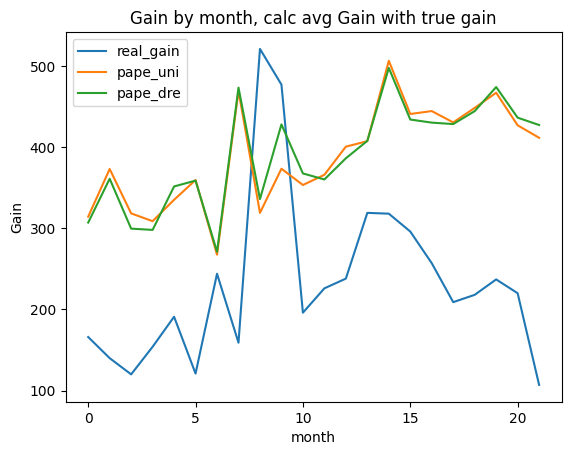

In [416]:
plt.plot([i for i in range(len(gain_true)-2)], gain_true['g_real'][2:])
plt.plot([i for i in range(len(gain_true)-2)], est_gain_uni)
plt.plot([i for i in range(len(gain_true)-2)], est_gain_dre)
plt.legend(['real_gain', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('Gain')
plt.title('Gain by month, calc avg Gain with true gain')

Text(0.5, 1.0, 'loss_keep by month')

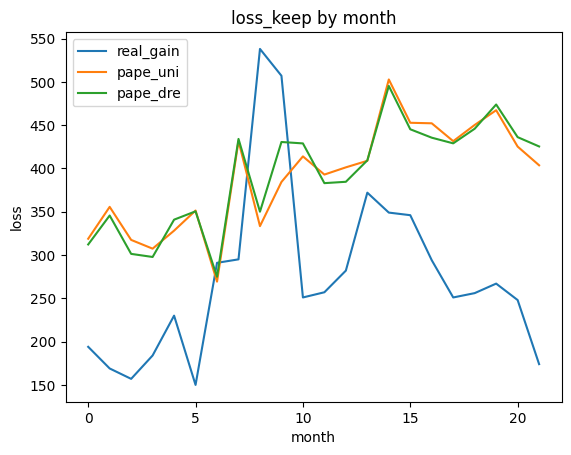

In [417]:
plt.plot([i for i in range(len(gain_true)-2)], keep_loss['loss'][2:])
plt.plot([i for i in range(len(gain_true)-2)], est_loss_keep_uni)
plt.plot([i for i in range(len(gain_true)-2)], est_loss_keep_dre)
plt.legend(['real_gain', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('loss')
plt.title('loss_keep by month')

Text(0.5, 1.0, 'loss_retrain by month')

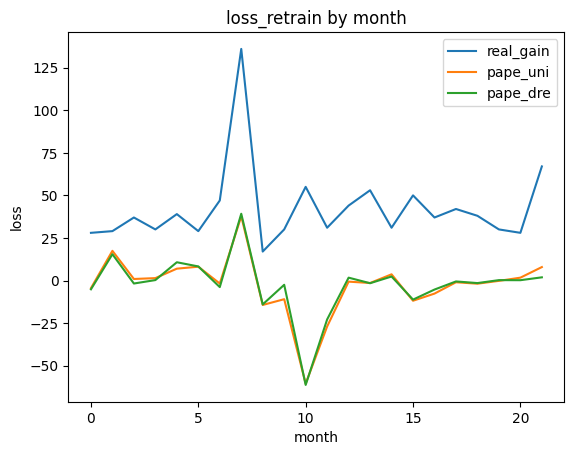

In [418]:
plt.plot([i for i in range(len(gain_true)-2)], retrain_loss['loss'][2:])
plt.plot([i for i in range(len(gain_true)-2)], est_loss_retrain_uni)
plt.plot([i for i in range(len(gain_true)-2)], est_loss_retrain_dre)
plt.legend(['real_gain', 'pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('loss')
plt.title('loss_retrain by month')

Text(0.5, 1.0, 'loss_retrain difference by month')

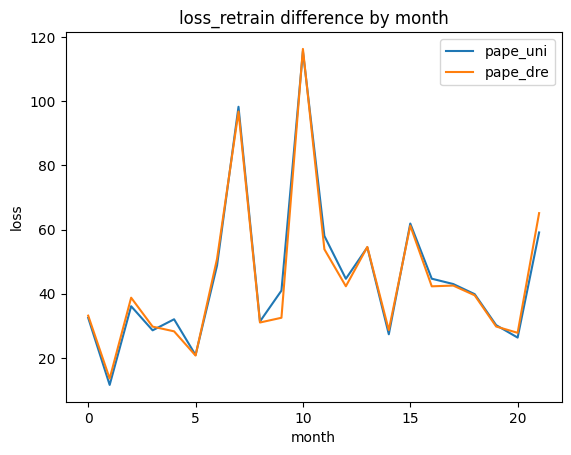

In [419]:
# plt.plot([i for i in range(len(gain_true)-2)], retrain_loss['loss'][2:])
plt.plot([i for i in range(len(gain_true)-2)], retrain_loss['loss'][2:] - est_loss_retrain_uni)
plt.plot([i for i in range(len(gain_true)-2)], retrain_loss['loss'][2:] - est_loss_retrain_dre)
plt.legend(['pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('loss')
plt.title('loss_retrain difference by month')

Text(0.5, 1.0, 'loss_keep difference by month')

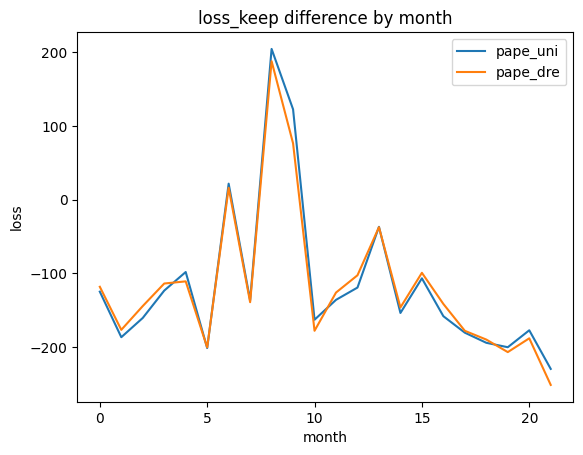

In [420]:
# plt.plot([i for i in range(len(gain_true)-2)], retrain_loss['loss'][2:])
plt.plot([i for i in range(len(gain_true)-2)], keep_loss['loss'][2:] - est_loss_keep_uni)
plt.plot([i for i in range(len(gain_true)-2)], keep_loss['loss'][2:] - est_loss_keep_dre)
plt.legend(['pape_uni', 'pape_dre'])
plt.xlabel('month')
plt.ylabel('loss')
plt.title('loss_keep difference by month')

In [421]:
gain_true['g_est_uni'] = [0] * 2 + est_gain_uni
gain_true['g_est_dre'] = [0] * 2 + est_gain_dre

<Axes: >

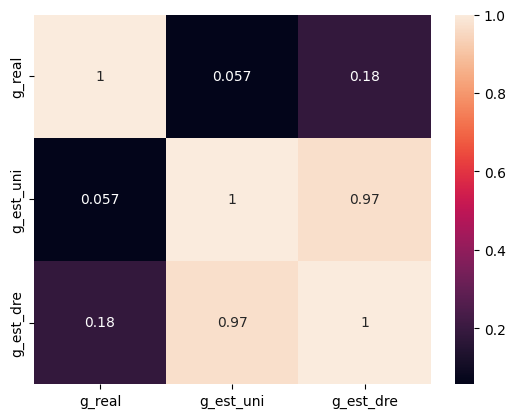

In [422]:
corr = gain_true[['g_real', 'g_est_uni', 'g_est_dre']][2:].corr()
sns.heatmap(corr, annot=True)

In [423]:
keep_loss['est_loss_keep_uni'] = [0] * 2 + est_loss_keep_uni
keep_loss['est_loss_keep_dre'] = [0] * 2 + est_loss_keep_dre

<Axes: >

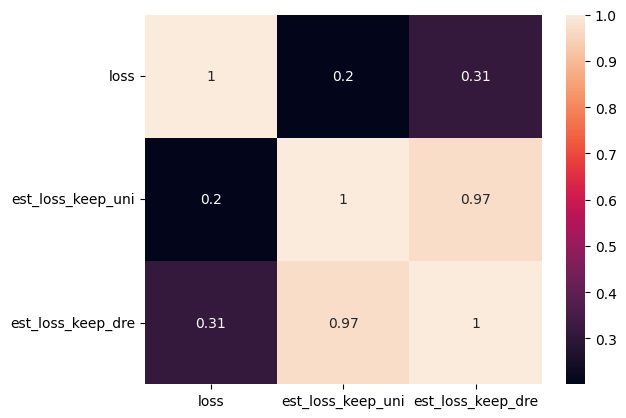

In [424]:
corr = keep_loss[['loss', 'est_loss_keep_uni', 'est_loss_keep_dre']][2:].corr()
sns.heatmap(corr, annot=True)

In [425]:
retrain_loss['est_loss_retrain_uni'] = [0] * 2 + est_loss_retrain_uni
retrain_loss['est_loss_retrain_dre'] = [0] * 2 + est_loss_retrain_dre

<Axes: >

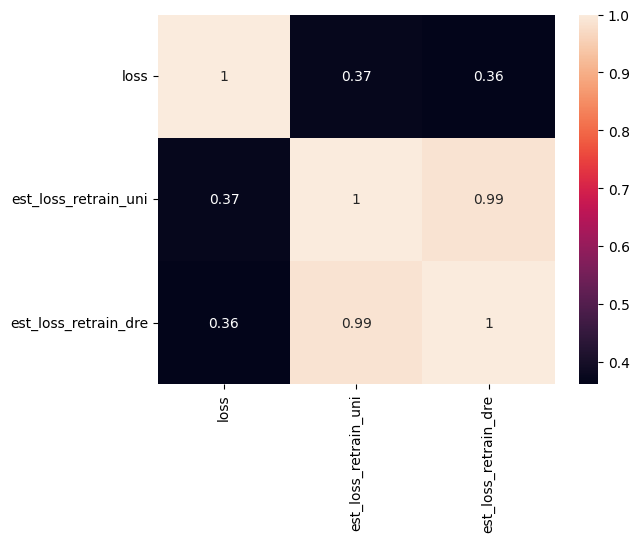

In [426]:
corr = retrain_loss[['loss', 'est_loss_retrain_uni', 'est_loss_retrain_dre']][2:].corr()
sns.heatmap(corr, annot=True)

## Conclusion
- API graph의 2015, 2016 데이터를 기반으로 Gain 추정 수식 검증
- 검증 결과 $loss_{keep}$과 $loss_{retrain}$은 각각 0.31, 0.36의 피어슨 상관계수를 보여 낮은 수준의 선형 관계를 확인
- 다만 $loss_{keep}$과 $loss_{retrain}$의 합인 $G^{hat}$은 $G^{real}$과 0.18의 피어슨 상관 계수를 보여 각각의 항목보다 낮은 추정 성능을 보임
- 그래프 상으로 보았을 때, $K_d$가 $K_p$에 비해 Optimal 값의 경향성 더 잘 추종함에도 오히려 $loss_{retrain}$의 성능이 높음(원인 분석 필요)
- 결과적으로 보았을 때, 본 추정 수식은 약하게 나마 $G^{real}$의 값을 추종하고 있으나, 실제 모델에 적용하기에는 아직 높은 오차를 보임
- 따라서 수식의 개선이 필요함